# Phase 3: Measure the Lesions

Turn masks into answers: **how many** lesions, **where** they are, **how big** they are and **what shape** they have.

The same measuring code is used for:
- the **ground-truth** masks (hand-drawn), to learn what benign and malignant lesions look like, and as the reference to check the models against;
- the **predicted** masks of any model (`unet`, `unet_multitask` or later `yolo`), chosen with the `MODEL` setting.

**Input:**
- `data/manifest.csv` and the ground-truth masks in `data/`
- `outputs/<MODEL>/masks/`: predicted test masks (created by `03_model_unet` or `05_model_yolo`)
- `outputs/<MODEL>/test_predictions.csv`: predicted class, if the model has one

**Output:**

| File | What it contains |
| ---- | ---------------- |
| `outputs/ground_truth/measurements.csv` | Every true lesion in every image (all splits) |
| `outputs/ground_truth/shape_by_class.png` | Benign vs malignant size and shape |
| `outputs/<MODEL>/measurements.csv` | Every predicted lesion in every test image |
| `outputs/<MODEL>/lesion_matches.csv` | Each true test lesion matched with its predicted lesion, with the errors |
| `outputs/<MODEL>/measurement_metrics.json` | How accurate the counts, sizes, locations and shapes are |
| `outputs/<MODEL>/measurement_by_version.csv` | v3: v1 / v2 / v3 measurement accuracy on the same test images |
| `outputs/<MODEL>/shape_rule.json` | v3: the irregular-shape limits used for predicted outlines (tuned on the out-of-fold masks) |
| `outputs/<MODEL>/size_comparison.png` | Predicted vs true lesion size |
| `outputs/<MODEL>/overlays/` | Every test image with its lesions outlined and numbered (for the app) |

> All sizes are in **pixels** because the images don't record the scanner's mm per pixel. Locations are positions **in the image**, not in the breast.

## 1. Imports

In [16]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from skimage.measure import label, regionprops, perimeter

## 2. Settings

In [17]:
DATA_DIR = Path('data')

MODEL = 'unet_multitask'      # whose predicted masks to measure: 'unet', 'unet_multitask' or 'yolo'

MODEL_DIR = Path('outputs') / MODEL
GROUND_TRUTH_DIR = Path('outputs/ground_truth')
OVERLAY_DIR = MODEL_DIR / 'overlays'
GROUND_TRUTH_DIR.mkdir(parents=True, exist_ok=True)
OVERLAY_DIR.mkdir(parents=True, exist_ok=True)

MIN_LESION_PIXELS = 50     # same as the other notebooks: smaller regions are noise
MATCH_IOU = 0.5            # a predicted lesion 'finds' a true lesion if they overlap at least this much (IoU)

# Simple shape rules, inspired by BI-RADS (approximate, not a clinical rule)
IRREGULAR_SOLIDITY = 0.90  # below this the outline has big dents       -> irregular
IRREGULAR_ROUGHNESS = 1.15 # above this the outline is wiggly or spiky  -> irregular
ROUND_AXIS_RATIO = 0.80    # short axis / long axis above this          -> round, otherwise oval

# v3: predicted outlines are smoother than hand-drawn ones, so they get their own irregular limits,
# tuned in section 4b on the out-of-fold masks from 03_model_unet. They start equal to the rule above.
TUNE_SHAPE_RULE = True
PRED_IRREGULAR_SOLIDITY = IRREGULAR_SOLIDITY
PRED_IRREGULAR_ROUGHNESS = IRREGULAR_ROUGHNESS

manifest = pd.read_csv(DATA_DIR / 'manifest.csv')
test_df = manifest[manifest['split'] == 'test'].reset_index(drop=True)
pool_df = manifest[manifest['fold'] >= 0].reset_index(drop=True)       # v3: cross-validation images
print(f'Measuring masks from: {MODEL_DIR}  |  {len(test_df)} test images')

Measuring masks from: outputs/unet_multitask  |  102 test images


## 3. The measuring functions

1. **Split the mask into lesions:** separate white regions (connected components) are separate lesions. Tiny specks are dropped, and lesions are numbered from largest to smallest.
2. **Measure each lesion:**

| Group | Measurement | How it's calculated |
| ----- | ----------- | ------------------- |
| Size | `area_px`, `area_pct` | Pixels inside the lesion, and as % of the whole image |
| | `box_width_px`, `box_height_px` | Size of the box around the lesion |
| | `longest_diameter_px` | Longest straight line across the lesion (like a radiologist's caliper) |
| | `equivalent_diameter_px` | Diameter of a circle with the same area |
| Location | `centre_x`, `centre_y` | Centre of the lesion in pixels (and `_frac`: 0 to 1 of width / height) |
| | `box_left` ... `box_bottom` | Box corners in pixels |
| | `depth_px`, `depth_frac` | Distance from the top edge (the skin) to the top of the lesion |
| | `horizontal_zone`, `depth_zone` | Left / centre / right and shallow / mid / deep third of the image |
| Shape | `circularity` | 4π × area / perimeter²: 1 = perfect circle, lower = less round |
| | `solidity` | Area / area of its convex hull (the outline with all dents filled in): 1 = no dents |
| | `axis_ratio` | Short axis / long axis: 1 = round, lower = elongated |
| | `edge_roughness` | Outline length / convex outline length: 1 = smooth, higher = wiggly or spiky |
| | `orientation` | Wider than tall, or taller than wide (taller than wide is a warning sign) |
| | `shape` | round / oval / irregular, from the rules in Settings |

In [18]:
def load_true_mask(mask_paths):
    """Merge an image's ground-truth masks into one True/False array."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    return np.any(masks, axis=0)


# v3: masks_dir lets us also measure the archived v1 / v2 masks (default: this model's current masks)
def load_pred_mask(image_path, masks_dir=None):
    """Load a model's predicted mask for an image (saved with the same folder and file name)."""
    masks_dir = masks_dir or MODEL_DIR / 'masks'
    return np.array(Image.open(masks_dir / image_path).convert('L')) > 127


def find_lesions(mask):
    """Split a True/False mask into separate lesions, largest first.
    Returns a list of (region, lesion_mask): the skimage region and a True/False mask of just that lesion."""
    labelled = label(mask, connectivity=2)                     # give each separate region its own number
    regions = [r for r in regionprops(labelled) if r.area >= MIN_LESION_PIXELS]
    regions.sort(key=lambda r: r.area, reverse=True)
    return [(r, labelled == r.label) for r in regions]


def zone(fraction, names):
    """Which third of the image a 0..1 position falls in, e.g. 0.1 -> names[0]."""
    return names[min(int(fraction * 3), 2)]


# v3: predicted=True uses the limits for predicted outlines (PRED_IRREGULAR_...)
def describe_shape(solidity, roughness, axis_ratio, predicted=False):
    """round / oval / irregular, using the simple rules from Settings."""
    max_solidity = PRED_IRREGULAR_SOLIDITY if predicted else IRREGULAR_SOLIDITY
    max_roughness = PRED_IRREGULAR_ROUGHNESS if predicted else IRREGULAR_ROUGHNESS
    if solidity < max_solidity or roughness > max_roughness:
        return 'irregular'
    return 'round' if axis_ratio >= ROUND_AXIS_RATIO else 'oval'


def measure_lesion(region, width, height, predicted=False):
    """Size, location and shape of one lesion (predicted=True for a model's outline, v3)."""
    top, left, bottom, right = region.bbox
    centre_y, centre_x = region.centroid
    box_width, box_height = right - left, bottom - top

    convex_perimeter = perimeter(region.image_convex)
    roughness = region.perimeter / convex_perimeter if convex_perimeter else 1.0
    axis_ratio = region.axis_minor_length / region.axis_major_length if region.axis_major_length else 1.0
    circularity = min(4 * np.pi * region.area / region.perimeter ** 2, 1.0) if region.perimeter else 1.0

    return {
        # Size
        'area_px': int(region.area),
        'area_pct': round(region.area / (width * height) * 100, 3),
        'box_width_px': int(box_width),
        'box_height_px': int(box_height),
        'longest_diameter_px': round(float(region.feret_diameter_max), 1),
        'equivalent_diameter_px': round(float(region.equivalent_diameter_area), 1),
        # Location
        'centre_x': round(float(centre_x), 1),
        'centre_y': round(float(centre_y), 1),
        'centre_x_frac': round(centre_x / width, 3),
        'centre_y_frac': round(centre_y / height, 3),
        'box_left': int(left), 'box_top': int(top), 'box_right': int(right), 'box_bottom': int(bottom),
        'depth_px': int(top),
        'depth_frac': round(top / height, 3),
        'horizontal_zone': zone(centre_x / width, ['left', 'centre', 'right']),
        'depth_zone': zone(centre_y / height, ['shallow', 'mid', 'deep']),
        # Shape
        'circularity': round(float(circularity), 3),
        'solidity': round(float(region.solidity), 3),
        'axis_ratio': round(float(axis_ratio), 3),
        'edge_roughness': round(float(roughness), 3),
        'orientation': 'taller than wide' if box_height > box_width else 'wider than tall',
        'shape': describe_shape(region.solidity, roughness, axis_ratio, predicted),
    }


def measure_mask(mask, predicted=False):
    """Measure every lesion in a mask. Returns one dict per lesion, numbered 1, 2, ... (largest first)."""
    height, width = mask.shape
    return [{'lesion': number, **measure_lesion(region, width, height, predicted)}
            for number, (region, _) in enumerate(find_lesions(mask), start=1)]


def iou_score(a, b):
    """Intersection over union of two True/False masks."""
    union = (a | b).sum()
    return float((a & b).sum() / union) if union else 1.0


# v3: the matching (section 6) is a function, defined here so section 4b can use it, so the same code can score the archived v1 / v2 masks
def match_lesions(masks_dir=None, frame=None):
    """Match the true and predicted lesions of every image in frame (default: the test images).
    Returns (matches, counts): one row per matched true lesion, and one row per image."""
    match_rows, count_rows = [], []
    frame = test_df if frame is None else frame
    for row in frame.itertuples():
        true_mask = load_true_mask(row.mask_paths)
        pred_mask = load_pred_mask(row.image_path, masks_dir)
        height, width = true_mask.shape
        diagonal = np.hypot(width, height)

        true_found, pred_found = find_lesions(true_mask), find_lesions(pred_mask)
        used = set()                                                  # predicted lesions already matched

        for t_number, (t_region, t_mask) in enumerate(true_found, start=1):
            # Best overlapping predicted lesion that isn't used yet
            best_iou, best = 0.0, None
            for p_number, (p_region, p_mask) in enumerate(pred_found, start=1):
                if p_number not in used:
                    iou = iou_score(t_mask, p_mask)
                    if iou > best_iou:
                        best_iou, best = iou, (p_number, p_region)

            if best is None or best_iou < MATCH_IOU:
                continue                                              # missed lesion
            p_number, p_region = best
            used.add(p_number)

            t = measure_lesion(t_region, width, height)
            p = measure_lesion(p_region, width, height, predicted=True)
            centre_distance = float(np.hypot(p['centre_x'] - t['centre_x'], p['centre_y'] - t['centre_y']))
            match_rows.append({
                'image_path': row.image_path, 'label': row.label,
                'true_lesion': t_number, 'pred_lesion': p_number, 'iou': round(best_iou, 3),
                'true_area_px': t['area_px'], 'pred_area_px': p['area_px'],
                'area_error_pct': round(abs(p['area_px'] - t['area_px']) / t['area_px'] * 100, 1),
                'true_diameter_px': t['longest_diameter_px'], 'pred_diameter_px': p['longest_diameter_px'],
                'diameter_error_pct': round(abs(p['longest_diameter_px'] - t['longest_diameter_px'])
                                            / t['longest_diameter_px'] * 100, 1),
                'centre_distance_px': round(centre_distance, 1),
                'centre_distance_pct': round(centre_distance / diagonal * 100, 2),
                'true_shape': t['shape'], 'pred_shape': p['shape'],
                'true_orientation': t['orientation'], 'pred_orientation': p['orientation'],
                'pred_solidity': p['solidity'], 'pred_roughness': p['edge_roughness'],   # v3: for tuning the shape rule
            })

        count_rows.append({'image_path': row.image_path, 'label': row.label,
                           'true_count': len(true_found), 'pred_count': len(pred_found),
                           'found': len(used)})

    return pd.DataFrame(match_rows), pd.DataFrame(count_rows)

In [19]:
# Try it on one image with two lesions
example = manifest[manifest['n_lesions'] >= 2].iloc[0]
print(example['image_path'])
pd.DataFrame(measure_mask(load_true_mask(example['mask_paths'])))

benign/benign (100).png


,lesion,area_px,area_pct,box_width_px,box_height_px,longest_diameter_px,equivalent_diameter_px,centre_x,centre_y,centre_x_frac,...,depth_px,depth_frac,horizontal_zone,depth_zone,circularity,solidity,axis_ratio,edge_roughness,orientation,shape
0,1,7090,4.641,101,96,121.3,95.0,253.1,177.5,0.784,...,126,0.266,right,mid,0.814,0.985,0.654,1.014,wider than tall,oval
1,2,2921,1.912,71,51,73.4,61.0,62.3,132.0,0.193,...,107,0.226,left,shallow,0.870,0.979,0.712,1.006,wider than tall,oval


## 4. Ground truth: what do benign and malignant lesions look like?

We measure every hand-drawn lesion in **all** images (train, val and test) to see whether size and shape differ between the classes. If they do, the measurements are useful on their own, not just as a description.

In [20]:
rows = []
for row in manifest[manifest['label'] != 'normal'].itertuples():
    for lesion in measure_mask(load_true_mask(row.mask_paths)):
        rows.append({'image_path': row.image_path, 'label': row.label, 'split': row.split, **lesion})

true_lesions = pd.DataFrame(rows)
true_lesions.to_csv(GROUND_TRUTH_DIR / 'measurements.csv', index=False)
print(f'{len(true_lesions)} true lesions measured')

true_lesions.groupby('label')[['area_pct', 'longest_diameter_px', 'circularity', 'solidity',
                               'axis_ratio', 'edge_roughness']].median().round(3)

576 true lesions measured


,area_pct,longest_diameter_px,circularity,solidity,axis_ratio,edge_roughness
label,,,,,,
benign,3.106,158.8,0.781,0.981,0.571,1.007
malignant,12.140,297.8,0.559,0.884,0.646,1.092


In [21]:
# % of lesions in each class that are irregular / taller than wide
pd.DataFrame({
    'irregular_%': true_lesions.groupby('label')['shape'].apply(lambda s: (s == 'irregular').mean() * 100),
    'taller_than_wide_%': true_lesions.groupby('label')['orientation'].apply(lambda s: (s == 'taller than wide').mean() * 100),
}).round(1)

,irregular_%,taller_than_wide_%
label,,
benign,1.3,1.6
malignant,58.8,11.6


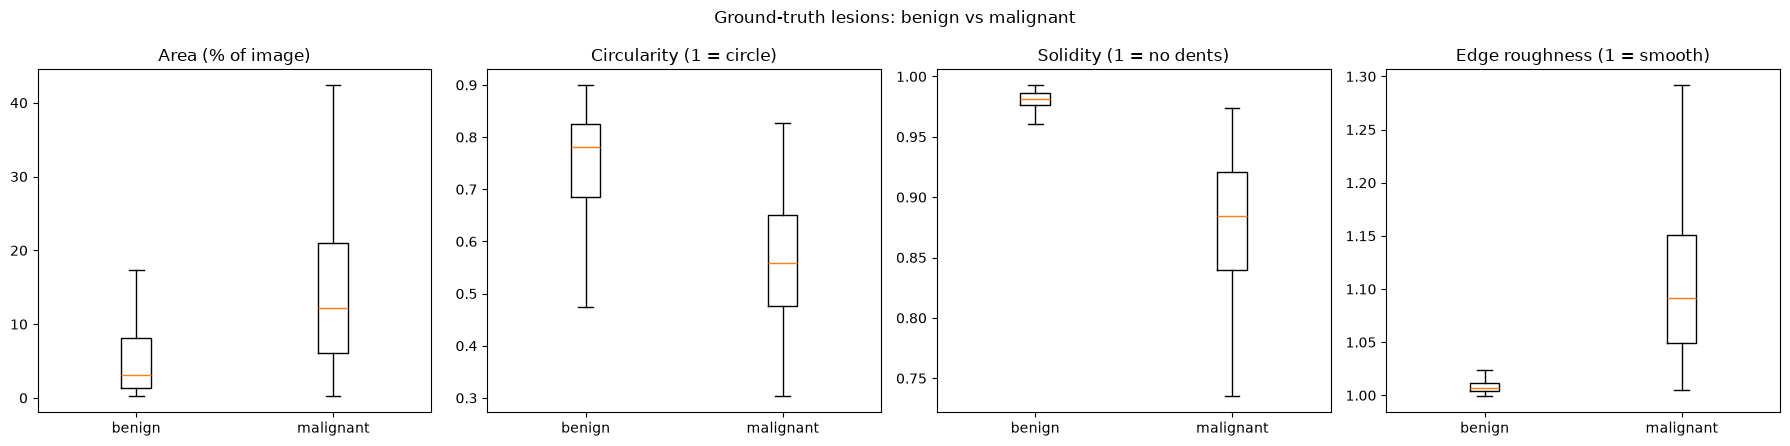

In [22]:
features = [('area_pct', 'Area (% of image)'), ('circularity', 'Circularity (1 = circle)'),
            ('solidity', 'Solidity (1 = no dents)'), ('edge_roughness', 'Edge roughness (1 = smooth)')]

fig, axes = plt.subplots(1, len(features), figsize=(18, 4.5))
for ax, (column, title) in zip(axes, features):
    data = [true_lesions.loc[true_lesions['label'] == c, column] for c in ['benign', 'malignant']]
    ax.boxplot(data, tick_labels=['benign', 'malignant'], showfliers=False)
    ax.set_title(title)

plt.suptitle('Ground-truth lesions: benign vs malignant')
plt.tight_layout()
plt.savefig(GROUND_TRUTH_DIR / 'shape_by_class.png', dpi=120, bbox_inches='tight')
plt.show()

## 4b. v3: Shape rule for predicted outlines (tuned on the out-of-fold masks)

Model outlines are smoother than hand-drawn ones (v3 at mask 0.5: predicted malignant solidity 0.957 vs 0.915 for the true lesions), so with the same rule almost no predicted lesion is labelled irregular.

We use the **out-of-fold masks** saved by `03_model_unet`: each of the 567 cross-validation images was predicted by the model that didn't train on it, so the test set isn't touched. For every matched lesion we know its **true** shape label (from the hand-drawn outline) and the **predicted** outline's solidity and roughness. We try many limits and keep the pair with the best **balanced accuracy**: the average of "% of irregular lesions called irregular" and "% of regular lesions called regular", so the rare irregular lesions count as much as the common ones.

The true masks keep the original rule. Round vs oval doesn't change.

> **Note:** the out-of-fold masks come from single models, while test masks average 5 models (a bit smoother still).

In [23]:
oof_mask_dir = MODEL_DIR / 'oof_masks'
if TUNE_SHAPE_RULE and oof_mask_dir.exists():
    oof_matches, _ = match_lesions(oof_mask_dir, pool_df[pool_df['label'] != 'normal'])
    true_irregular = (oof_matches['true_shape'] == 'irregular').values

    rows = []
    for max_solidity in np.round(np.arange(0.88, 0.981, 0.01), 2):
        for max_roughness in np.round(np.arange(1.02, 1.151, 0.01), 2):
            called_irregular = ((oof_matches['pred_solidity'] < max_solidity) |
                                (oof_matches['pred_roughness'] > max_roughness)).values
            irregular_caught = (called_irregular & true_irregular).sum() / max(true_irregular.sum(), 1)
            regular_correct = (~called_irregular & ~true_irregular).sum() / max((~true_irregular).sum(), 1)
            rows.append({'solidity_below': max_solidity, 'roughness_above': max_roughness,
                         'irregular_called_irregular': irregular_caught, 'regular_called_regular': regular_correct,
                         'balanced_accuracy': (irregular_caught + regular_correct) / 2})
    shape_grid = pd.DataFrame(rows)

    same_rule = shape_grid[(shape_grid['solidity_below'] == IRREGULAR_SOLIDITY) &
                           (shape_grid['roughness_above'] == IRREGULAR_ROUGHNESS)].iloc[0]
    best = shape_grid.loc[shape_grid['balanced_accuracy'].idxmax()]
    PRED_IRREGULAR_SOLIDITY, PRED_IRREGULAR_ROUGHNESS = float(best['solidity_below']), float(best['roughness_above'])

    shape_rule = {'pred_irregular_solidity': PRED_IRREGULAR_SOLIDITY, 'pred_irregular_roughness': PRED_IRREGULAR_ROUGHNESS,
                  'true_irregular_solidity': IRREGULAR_SOLIDITY, 'true_irregular_roughness': IRREGULAR_ROUGHNESS,
                  'round_axis_ratio': ROUND_AXIS_RATIO, 'tuned_on': f'{len(oof_matches)} out-of-fold lesions '
                  f'({int(true_irregular.sum())} irregular), best balanced accuracy'}
    (MODEL_DIR / 'shape_rule.json').write_text(json.dumps(shape_rule, indent=2))

    print(f'{len(oof_matches)} matched out-of-fold lesions, {int(true_irregular.sum())} of them irregular')
    print(f'Predicted outlines: irregular if solidity < {PRED_IRREGULAR_SOLIDITY:.2f} or roughness > {PRED_IRREGULAR_ROUGHNESS:.2f}')
    display(pd.DataFrame({'same rule as true masks': same_rule, 'tuned rule': best}).round(3))
else:
    print(f'No out-of-fold masks in {oof_mask_dir}: predicted outlines use the same rule as the true masks')

393 matched out-of-fold lesions, 79 of them irregular
Predicted outlines: irregular if solidity < 0.96 or roughness > 1.09


,same rule as true masks,tuned rule
solidity_below,0.900,0.960
roughness_above,1.150,1.090
irregular_called_irregular,0.215,0.861
regular_called_regular,0.933,0.732
balanced_accuracy,0.574,0.797


## 5. Measure the model's predicted masks (test images)

In [24]:
rows = []
for row in test_df.itertuples():
    for lesion in measure_mask(load_pred_mask(row.image_path), predicted=True):
        rows.append({'image_path': row.image_path, 'label': row.label, **lesion})

pred_lesions = pd.DataFrame(rows)
pred_lesions.to_csv(MODEL_DIR / 'measurements.csv', index=False)
print(f'{len(pred_lesions)} predicted lesions in {len(test_df)} test images')
pred_lesions.head()

84 predicted lesions in 102 test images


,image_path,label,lesion,area_px,area_pct,box_width_px,box_height_px,longest_diameter_px,equivalent_diameter_px,centre_x,...,depth_px,depth_frac,horizontal_zone,depth_zone,circularity,solidity,axis_ratio,edge_roughness,orientation,shape
0,normal/normal (28).png,normal,1,21186,4.498,255,217,284.1,164.2,538.4,...,39,0.063,right,shallow,0.202,0.586,0.561,1.478,wider than tall,irregular
1,normal/normal (56).png,normal,1,25690,5.630,207,163,219.1,180.9,667.8,...,78,0.130,right,shallow,0.811,0.986,0.752,1.010,wider than tall,oval
2,normal/normal (56).png,normal,2,1893,0.415,48,60,61.6,49.1,291.1,...,53,0.089,centre,shallow,0.702,0.898,0.765,1.047,taller than wide,irregular
3,normal/normal (58).png,normal,1,3383,1.254,94,48,96.1,65.6,317.5,...,136,0.279,centre,shallow,0.718,0.960,0.463,1.003,wider than tall,irregular
4,benign/benign (10).png,benign,1,33930,8.492,220,203,222.6,207.8,135.0,...,63,0.108,left,shallow,0.856,0.988,0.907,1.002,wider than tall,round


## 6. How accurate are the measurements?

We compare the model's lesions with the true lesions in each test image:

1. **Count:** does the model find the right number of lesions?
2. **Matching:** each true lesion is paired with the predicted lesion that overlaps it most. The pair counts as a **match** if their IoU is at least `MATCH_IOU`.
   - **Found** = matched true lesions
   - **Missed** = true lesions with no match
   - **False** = predicted lesions with no match
3. **For each match:** how far off are the size, the centre and the shape?

In [25]:
matches, counts = match_lesions()
matches.to_csv(MODEL_DIR / 'lesion_matches.csv', index=False)
print(f'{len(matches)} true lesions matched')

73 true lesions matched


In [26]:
# v3: the metrics are now a function, so every version is scored the same way
def measurement_metrics(matches, counts):
    """Count, size, location and shape accuracy from match_lesions()."""
    found = counts['found'].sum()
    missed = (counts['true_count'] - counts['found']).sum()
    false = (counts['pred_count'] - counts['found']).sum()
    normal = counts['label'] == 'normal'
    irregular = matches['true_shape'] == 'irregular'

    metrics = {
        # Counting
        'count_accuracy': float((counts['true_count'] == counts['pred_count']).mean()),
        'lesions_found': int(found), 'lesions_missed': int(missed), 'false_lesions': int(false),
        'lesion_recall': float(found / max(found + missed, 1)),          # % of true lesions found
        'lesion_precision': float(found / max(found + false, 1)),        # % of predicted lesions that are real
        'normal_images_with_false_lesion': float((counts.loc[normal, 'pred_count'] > 0).mean()),
        # Size and location (median over matched lesions)
        'median_area_error_pct': float(matches['area_error_pct'].median()),
        'median_diameter_error_pct': float(matches['diameter_error_pct'].median()),
        'median_centre_distance_px': float(matches['centre_distance_px'].median()),
        'median_centre_distance_pct_of_diagonal': float(matches['centre_distance_pct'].median()),
        # Shape
        'shape_agreement': float((matches['true_shape'] == matches['pred_shape']).mean()),
        'orientation_agreement': float((matches['true_orientation'] == matches['pred_orientation']).mean()),
        # v3: of the found lesions that are really irregular, how many does the model also call irregular?
        'irregular_lesions_found': int(irregular.sum()),
        'irregular_shape_correct': int((irregular & (matches['pred_shape'] == 'irregular')).sum()),
    }
    metrics['lesion_f1'] = 2 * metrics['lesion_precision'] * metrics['lesion_recall'] / max(
        metrics['lesion_precision'] + metrics['lesion_recall'], 1e-8)
    return metrics


metrics = measurement_metrics(matches, counts)
(MODEL_DIR / 'measurement_metrics.json').write_text(json.dumps(metrics, indent=2))
for name, value in metrics.items():
    print(f'{name:40s} {value:.3f}' if isinstance(value, float) else f'{name:40s} {value}')

count_accuracy                           0.873
lesions_found                            73
lesions_missed                           13
false_lesions                            11
lesion_recall                            0.849
lesion_precision                         0.869
normal_images_with_false_lesion          0.176
median_area_error_pct                    6.500
median_diameter_error_pct                4.100
median_centre_distance_px                3.700
median_centre_distance_pct_of_diagonal   0.500
shape_agreement                          0.808
orientation_agreement                    0.959
irregular_lesions_found                  9
irregular_shape_correct                  7
lesion_f1                                0.859


### v2: compared with v1, and shape check

1. **v1 vs now:** the measurement results above next to the archived v1 results for the same model and test images. A positive change is better for found, precision, recall, F1, count accuracy and agreement; a negative change is better for missed, false lesions and errors.
2. **Shape check:** median shape features of the predicted lesions vs the real lesions in the test set. If the predicted outlines are much rougher (higher edge roughness) or less round (lower circularity) than the real ones, the shape labels will be wrong even when the lesion is found. In v1, predicted benign outlines had roughness 1.109 vs 1.008 for real ones, because of how masks were enlarged in `03_model_unet` (fixed in v2 with `SMOOTH_MASKS`).

**v3 change:** v3 cleaning removed 2 images from the test set (104 → 102), so the archived v1 / v2 summary numbers are no longer on the same images. Instead, the archived v1 and v2 **masks** are re-measured here on today's 102 test images with exactly the same code, so all three versions are compared fairly. All versions use the same shape rule (section 4b). `v3 (mask 0.50)` is the first v3 run, archived in `outputs/archive/v3_mask050/`. The new rows `irregular_lesions_found` / `irregular_shape_correct` show whether the 384 px U-Net keeps the irregular outlines of malignant lesions (v2: too smooth).

In [27]:
# v3: re-measure the archived v1 and v2 masks on today's test images, so all versions use the same images
ARCHIVE = Path('outputs/archive')
versions = {'v1': ARCHIVE / 'v1_baseline' / MODEL / 'masks',
            'v2': ARCHIVE / 'v2_postprocessing' / MODEL / 'masks',
            'v3 (mask 0.50)': ARCHIVE / 'v3_mask050' / MODEL / 'masks'}     # v3: first v3 run, before the mask threshold tuning

results = {}
for version, masks_dir in versions.items():
    if all((masks_dir / p).exists() for p in test_df['image_path']):
        results[version] = measurement_metrics(*match_lesions(masks_dir))
    else:
        print(f'{version}: archived masks missing for some test images, skipped')
results['v3'] = metrics

comparison = pd.DataFrame(results).astype(float).round(3)
if 'v1' in comparison:
    comparison['change vs v1'] = (comparison['v3'] - comparison['v1']).round(3)
comparison.to_csv(MODEL_DIR / 'measurement_by_version.csv')
display(comparison)

# v2: are the predicted outlines as smooth and round as the real ones? (test lesions, medians)
shape_columns = ['circularity', 'solidity', 'edge_roughness', 'axis_ratio']
test_true = pd.DataFrame([{'label': row.label, **lesion} for row in test_df[test_df['label'] != 'normal'].itertuples()
                          for lesion in measure_mask(load_true_mask(row.mask_paths))])
pd.concat({'true': test_true.groupby('label')[shape_columns].median(),
           'predicted': pred_lesions[pred_lesions['label'] != 'normal'].groupby('label')[shape_columns].median()}).round(3)

,v1,v2,v3 (mask 0.50),v3,change vs v1
count_accuracy,0.824,0.843,0.873,0.873,0.049
lesions_found,72.000,72.000,73.000,73.000,1.000
lesions_missed,14.000,14.000,13.000,13.000,-1.000
false_lesions,29.000,23.000,11.000,11.000,-18.000
lesion_recall,0.837,0.837,0.849,0.849,0.012
lesion_precision,0.713,0.758,0.869,0.869,0.156
normal_images_with_false_lesion,0.176,0.176,0.176,0.176,0.000
median_area_error_pct,8.600,8.600,6.500,6.500,-2.100
median_diameter_error_pct,4.300,4.150,4.100,4.100,-0.200
median_centre_distance_px,4.800,4.850,3.700,3.700,-1.100


circularity  solidity  edge_roughness  axis_ratio
          label                                                       
true      benign           0.812     0.982           1.008       0.644
          malignant        0.582     0.915           1.068       0.634
predicted benign           0.827     0.981           1.001       0.631
          malignant        0.691     0.957           1.031       0.687

In [28]:
# Number of lesions: true (rows) vs predicted (columns)
pd.crosstab(counts['true_count'], counts['pred_count'], rownames=['true'], colnames=['predicted'])

predicted,0,1,2
true,,,
0,14,2,1
1,7,75,2
2,0,1,0


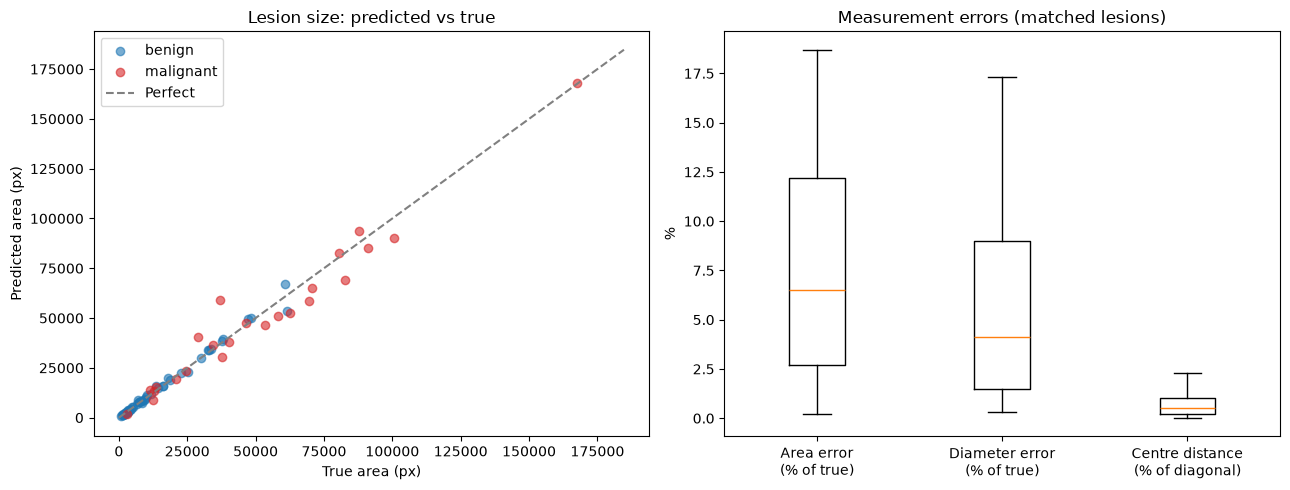

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: predicted vs true area (points on the dashed line = perfect)
for class_name, color in [('benign', 'tab:blue'), ('malignant', 'tab:red')]:
    part = matches[matches['label'] == class_name]
    axes[0].scatter(part['true_area_px'], part['pred_area_px'], alpha=0.6, color=color, label=class_name)
limit = max(matches['true_area_px'].max(), matches['pred_area_px'].max()) * 1.1
axes[0].plot([0, limit], [0, limit], color='grey', linestyle='--', label='Perfect')
axes[0].set_xlabel('True area (px)')
axes[0].set_ylabel('Predicted area (px)')
axes[0].set_title('Lesion size: predicted vs true')
axes[0].legend()

# Right: how far off the size and centre are
axes[1].boxplot([matches['area_error_pct'], matches['diameter_error_pct'], matches['centre_distance_pct']],
                tick_labels=['Area error\n(% of true)', 'Diameter error\n(% of true)', 'Centre distance\n(% of diagonal)'],
                showfliers=False)
axes[1].set_ylabel('%')
axes[1].set_title('Measurement errors (matched lesions)')

plt.tight_layout()
plt.savefig(MODEL_DIR / 'size_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Lesion report for one image

This is what the app will show for an uploaded scan: the predicted class (if the model has one), a numbered outline of every lesion and a table of measurements.

**Red** = predicted lesion with its number and box, **green** = true outline (only when the ground truth is known).

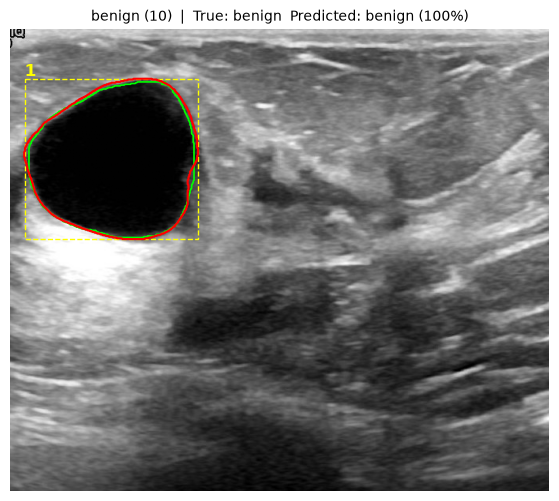

,lesion,area_px,area_pct,longest_diameter_px,centre_x,centre_y,depth_px,horizontal_zone,depth_zone,shape,orientation,circularity,solidity
0,1,33930,8.492,222.6,135.0,165.8,63,left,shallow,round,wider than tall,0.856,0.988


In [30]:
# Predicted class for each test image, if this model has a classification head
predictions_file = MODEL_DIR / 'test_predictions.csv'
class_predictions = pd.read_csv(predictions_file) if predictions_file.exists() else pd.DataFrame()
HAS_CLASSES = 'predicted' in class_predictions.columns


def prediction_text(image_path):
    """e.g. 'Predicted: benign (91%)', or '' if the model doesn't classify."""
    if not HAS_CLASSES:
        return ''
    row = class_predictions[class_predictions['image_path'] == image_path].iloc[0]
    return f"Predicted: {row['predicted']} ({row['prob_' + row['predicted']]:.0%})"


def draw_report(image_path, mask, true_mask=None, title=''):
    """Image with every lesion outlined, boxed and numbered. Returns the figure."""
    image = Image.open(DATA_DIR / image_path).convert('L')
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(image, cmap='gray')

    if true_mask is not None and true_mask.any():
        ax.contour(true_mask, levels=[0.5], colors='lime', linewidths=1.2)               # true outline

    for number, (region, lesion_mask) in enumerate(find_lesions(mask), start=1):
        top, left, bottom, right = region.bbox
        ax.contour(lesion_mask, levels=[0.5], colors='red', linewidths=1.5)              # predicted outline
        ax.add_patch(patches.Rectangle((left, top), right - left, bottom - top,
                                       fill=False, edgecolor='yellow', linestyle='--', linewidth=1))
        ax.text(left, top - 4, str(number), color='yellow', fontsize=12, fontweight='bold')   # lesion number

    ax.set_title(title, fontsize=10)
    ax.axis('off')
    return fig


# Example: a test image with a lesion
sample = test_df[test_df['label'] != 'normal'].iloc[0]
sample_mask = load_pred_mask(sample['image_path'])
title = f"{Path(sample['image_path']).stem}  |  True: {sample['label']}  {prediction_text(sample['image_path'])}"
draw_report(sample['image_path'], sample_mask, load_true_mask(sample['mask_paths']), title)
plt.show()

report_columns = ['lesion', 'area_px', 'area_pct', 'longest_diameter_px', 'centre_x', 'centre_y', 'depth_px',
                  'horizontal_zone', 'depth_zone', 'shape', 'orientation', 'circularity', 'solidity']
sample_lesions = measure_mask(sample_mask, predicted=True)
pd.DataFrame(sample_lesions)[report_columns] if sample_lesions else 'No lesion found'

## 8. Save an overlay for every test image (for the app)

In [31]:
for row in test_df.itertuples():
    mask = load_pred_mask(row.image_path)
    n_lesions = len(find_lesions(mask))
    title = (f'{Path(row.image_path).stem}  |  True: {row.label}  {prediction_text(row.image_path)}'
             f'  |  Lesions found: {n_lesions}')

    fig = draw_report(row.image_path, mask, load_true_mask(row.mask_paths), title)
    save_path = OVERLAY_DIR / row.image_path                  # e.g. overlays/benign/benign (12).png
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=100, bbox_inches='tight')
    plt.close(fig)                                            # don't display, just save

print(f'Saved {len(test_df)} overlays to {OVERLAY_DIR}')

Saved 102 overlays to outputs/unet_multitask/overlays
